# Лабораторная работа №2. Классификация. Нейронные сети

## 1. Введение

**Цель работы:** изучить методы классификации из библиотеки Scikit-Learn и познакомиться с нейронными сетями на TensorFlow/Keras с мониторингом обучения в TensorBoard.

**Задачи:**
1. Выбрать и подготовить датасет, построить модели пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ (LDA), метод опорных векторов (SVM), k ближайших соседей (kNN).
2. Сравнить модели по Accuracy, Precision, Recall, F1 и AUC-ROC.
3. Подобрать гиперпараметры каждого метода и исследовать их влияние на качество.
4. Реализовать нейронную сеть на TensorFlow, исследовать гиперпараметры, визуализировать обучение в TensorBoard.

In [1]:
import os
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import sklearn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

FIG_DIR = Path("figures")
RES_DIR = Path("results")
LOG_DIR = Path("logs")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | tensorflow 2.21.0 | pandas 3.1.1


## 2. Выбор и подготовка датасета

Используется датасет дорожно-транспортных происшествий в Великобритании (`accident_data.csv`, тот же, что в ЛР1). Одна строка — одно транспортное средство, участвовавшее в ДТП.

**Задача:** по условиям происшествия предсказать его серьёзность. Исходный признак `Accident_Severity` имеет три класса (Slight, Serious, Fatal) с сильным дисбалансом; для классических метрик (precision, recall, F1, ROC) задача сведена к **бинарной**: класс `1` — тяжёлое ДТП (Serious или Fatal), класс `0` — лёгкое (Slight).

In [2]:
candidates = [Path("accident_data.csv"), Path("../lab1/accident_data.csv"), Path("../../lab1/accident_data.csv")]
data_path = next(p for p in candidates if p.exists())
df_raw = pd.read_csv(data_path)
print(data_path, df_raw.shape)
print(df_raw.dtypes)
df_raw.head()

../lab1/accident_data.csv (670679, 14)
Index                          str
Accident_Severity              str
Accident Date                  str
Latitude                   float64
Light_Conditions               str
District Area                  str
Longitude                  float64
Number_of_Casualties         int64
Number_of_Vehicles           int64
Road_Surface_Conditions        str
Road_Type                      str
Urban_or_Rural_Area            str
Weather_Conditions             str
Vehicle_Type                   str
dtype: object


,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200701BS64157,Serious,05-06-2019,51.506187,Darkness - lights lit,Kensington and Chelsea,-0.209082,1,2,Dry,Single carriageway,Urban,Fine no high winds,Car
1,200701BS65737,Serious,02-07-2019,51.495029,Daylight,Kensington and Chelsea,-0.173647,1,2,Wet or damp,Single carriageway,Urban,Raining no high winds,Car
2,200701BS66127,Serious,26-08-2019,51.517715,Darkness - lighting unknown,Kensington and Chelsea,-0.210215,1,3,Dry,NaN,Urban,NaN,Taxi/Private hire car
3,200701BS66128,Serious,16-08-2019,51.495478,Daylight,Kensington and Chelsea,-0.202731,1,4,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,200701BS66837,Slight,03-09-2019,51.488576,Darkness - lights lit,Kensington and Chelsea,-0.192487,1,2,Dry,NaN,Urban,NaN,Other vehicle


In [3]:
print(df_raw.isna().sum())
print(df_raw["Accident_Severity"].value_counts())
print(df_raw.select_dtypes(exclude="number").nunique())
df_raw.describe()

Index                          0
Accident_Severity              0
Accident Date                  0
Latitude                      25
Light_Conditions               0
District Area                  0
Longitude                     26
Number_of_Casualties           0
Number_of_Vehicles             0
Road_Surface_Conditions      742
Road_Type                   4580
Urban_or_Rural_Area           15
Weather_Conditions         14351
Vehicle_Type                   0
dtype: int64
Accident_Severity
Slight     572307
Serious     89568
Fatal        8804
Name: count, dtype: int64


Index                      431020
Accident_Severity               3
Accident Date                2556
Light_Conditions                5
District Area                 422
Road_Surface_Conditions         5
Road_Type                       5
Urban_or_Rural_Area             3
Weather_Conditions              8
Vehicle_Type                   16
dtype: int64


,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles
count,670654.000000,670653.000000,670679.000000,670679.000000
mean,52.554015,-1.431468,1.357013,1.831237
std,1.406956,1.383224,0.824759,0.715443
min,49.914430,-7.516225,1.000000,1.000000
25%,51.490672,-2.332413,1.000000,1.000000
50%,52.316381,-1.411817,1.000000,2.000000
75%,53.453395,-0.233365,1.000000,2.000000
max,60.757544,1.762010,68.000000,32.000000


**Характеристика признаков**

| Признак | Тип | Использование |
|---|---|---|
| Latitude, Longitude | числовой | признак (есть пропуски, медианная импутация) |
| Number_of_Casualties, Number_of_Vehicles | числовой | признак |
| Accident Date | дата | из неё извлекаются `Month` и `Weekday` |
| Light_Conditions, Road_Surface_Conditions, Road_Type, Urban_or_Rural_Area, Weather_Conditions, Vehicle_Type | категориальный | признак, One-Hot кодирование, пропуски заменяются модой |
| District Area | категориальный (422 значения) | не используется |
| Index | идентификатор ДТП | не используется (повторяется у разных машин одного ДТП) |
| Accident_Severity | целевой | `Slight` → 0, `Serious`/`Fatal` → 1 |

Предобработка: пропуски заполняются внутри `ColumnTransformer` (числовые — медианой, категориальные — модой), числовые признаки масштабируются `MinMaxScaler` в [0, 1] (нужно для Multinomial/ComplementNB, которым требуются неотрицательные значения, и полезно для SVM/kNN/LDA), категориальные кодируются `OneHotEncoder`. Трансформер обучается **только на обучающей выборке**.

In [4]:
df = df_raw.copy()
df["Accident Date"] = pd.to_datetime(df["Accident Date"], format="%d-%m-%Y")
df["Month"] = df["Accident Date"].dt.month
df["Weekday"] = df["Accident Date"].dt.dayofweek

CLASS_NAMES = {0: "Slight", 1: "Serious/Fatal"}
num_cols = ["Latitude", "Longitude", "Number_of_Casualties", "Number_of_Vehicles", "Month", "Weekday"]
cat_cols = ["Light_Conditions", "Road_Surface_Conditions", "Road_Type", "Urban_or_Rural_Area",
            "Weather_Conditions", "Vehicle_Type"]

X_all = df[num_cols + cat_cols]
y_all = df["Accident_Severity"].isin(["Serious", "Fatal"]).astype(int)

print(X_all.shape, y_all.shape)
print(y_all.map(CLASS_NAMES).value_counts())
print(y_all.value_counts(normalize=True).round(4))

(670679, 12) (670679,)
Accident_Severity
Slight           572307
Serious/Fatal     98372
Name: count, dtype: int64
Accident_Severity
0    0.8533
1    0.1467
Name: proportion, dtype: float64


/var/folders/4h/sbh75ykd1h5_rk7j825xt_4r0000gn/T/ipykernel_31207/455743570.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Weekday"] = df["Accident Date"].dt.dayofweek


## 3. Разбиение выборки

Полный датасет (670 тыс. строк) слишком велик для SVM и kNN с перебором параметров, поэтому берётся **стратифицированная подвыборка 30 000 объектов**, которая затем делится на обучающую (80%) и тестовую (20%) части функцией `train_test_split` со `stratify` и `random_state=42`. Тест не используется при подборе гиперпараметров — только в финальной оценке.

In [5]:
N_SAMPLE = 30000
X_s, _, y_s, _ = train_test_split(X_all, y_all, train_size=N_SAMPLE, stratify=y_all, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, stratify=y_s, random_state=SEED)

print("train:", X_train.shape, "test:", X_test.shape)
print("train share of class 1:", round(y_train.mean(), 4), "| test share of class 1:", round(y_test.mean(), 4))
print("missing in train:")
print(X_train.isna().sum()[lambda s: s > 0])

train: (24000, 12) test: (6000, 12)
train share of class 1: 0.1467 | test share of class 1: 0.1467
missing in train:
Latitude                     4
Longitude                    4
Road_Surface_Conditions     22
Road_Type                  192
Urban_or_Rural_Area          1
Weather_Conditions         497
dtype: int64


In [6]:
def make_preprocessor():
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", MinMaxScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])


preprocessor = make_preprocessor()
Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("transformed:", Xtr.shape, Xte.shape, "| NaN left:", int(np.isnan(Xtr).sum()))
print("train min/max:", Xtr.min(), Xtr.max())

transformed: (24000, 48) (6000, 48) | NaN left: 0
train min/max: 0.0 1.0


## 4. Методы классификации

* **Наивный Байес** — применяет теорему Байеса с предположением условной независимости признаков. Варианты: `GaussianNB` (нормальное распределение признака), `MultinomialNB` (счётчики/неотрицательные признаки), `ComplementNB` (модификация Multinomial для несбалансированных классов), `BernoulliNB` (бинарные признаки). Все четыре варианта применимы к нашим признакам после One-Hot и MinMax.
* **Дерево решений** — рекурсивное разбиение по порогам признаков по критерию Джини или энтропии; регуляризуется глубиной и минимальным размером листа.
* **LDA** — линейная разделяющая поверхность в предположении нормальных классов с общей ковариационной матрицей; решатели `svd`, `lsqr`, `eigen`, возможна shrinkage-регуляризация ковариации.
* **SVM** — максимизация зазора между классами; ядро (`linear`, `rbf`), параметры `C` (штраф за ошибки) и `gamma` (ширина RBF).
* **kNN** — класс определяется голосованием `k` ближайших объектов; параметры `n_neighbors`, `weights`, метрика расстояния.

Положительный класс — `1` (тяжёлое ДТП). Precision, Recall, F1 считаются по нему (`pos_label=1`); AUC-ROC — по вероятностям (`predict_proba`) либо, для SVM, по значениям решающей функции (`decision_function`).

### Базовые модели (параметры по умолчанию)

In [7]:
def get_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def compute_metrics(y_true, y_pred, score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "auc_roc": roc_auc_score(y_true, score),
    }


baseline_models = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "BernoulliNB": BernoulliNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=SEED),
    "LDA": LinearDiscriminantAnalysis(),
    "SVM": SVC(random_state=SEED),
    "kNN": KNeighborsClassifier(),
}

rows = []
for name, model in baseline_models.items():
    t0 = time.time()
    model.fit(Xtr, y_train)
    fit_s = time.time() - t0
    pred = model.predict(Xte)
    score = get_score(model, Xte)
    rows.append({"model": name, **compute_metrics(y_test, pred, score), "fit_s": fit_s})

baseline_df = pd.DataFrame(rows).set_index("model")
baseline_df.to_csv(RES_DIR / "baseline_metrics.csv")
baseline_df.round(4)

,accuracy,precision,recall,f1,auc_roc,fit_s
model,,,,,,
GaussianNB,0.1648,0.1479,0.9864,0.2573,0.5762,0.0090
MultinomialNB,0.8533,0.0000,0.0000,0.0000,0.5785,0.0033
ComplementNB,0.6328,0.1869,0.4489,0.2639,0.5785,0.0026
BernoulliNB,0.8483,0.2973,0.0250,0.0461,0.6179,0.0078
DecisionTree,0.7447,0.1772,0.2034,0.1894,0.5206,0.1278
LDA,0.8530,0.4000,0.0045,0.0090,0.6240,0.0434
SVM,0.8533,0.0000,0.0000,0.0000,0.5373,12.4224
kNN,0.8390,0.2133,0.0364,0.0621,0.5369,0.0012


## 5. Настройка гиперпараметров

Подбор выполняется `GridSearchCV` по `Pipeline(предобработка → классификатор)` — предобработка обучается заново на каждом фолде, утечки нет. Кросс-валидация: `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`; лучшая конфигурация выбирается по **ROC-AUC** (`refit="roc_auc"`), параллельно считается F1. Выбор по AUC обусловлен дисбалансом классов (~14% тяжёлых ДТП): AUC не зависит от порога, а Accuracy при дисбалансе вводит в заблуждение.

SVM подбирается на стратифицированной подвыборке 6 000 объектов обучающей выборки (ускорение), затем лучшая конфигурация обучается на всей обучающей выборке.

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "f1": "f1"}


def prefix(grid):
    if isinstance(grid, dict):
        grid = [grid]
    return [{f"clf__{k}": v for k, v in g.items()} for g in grid]


def tune(name, estimator, grid, X, y):
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", estimator)])
    gs = GridSearchCV(pipe, prefix(grid), scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=2)
    t0 = time.time()
    gs.fit(X, y)
    n = len(gs.cv_results_["params"])
    print(f"{name}: {n} конфигураций x 3 фолда за {time.time() - t0:.1f} с | "
          f"AUC={gs.best_score_:.4f} | {gs.best_params_}")
    return gs


SEARCH_SPACES = {
    "GaussianNB": (GaussianNB(), {"var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]}),
    "MultinomialNB": (MultinomialNB(), {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]}),
    "ComplementNB": (ComplementNB(), {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0], "norm": [False, True]}),
    "BernoulliNB": (BernoulliNB(), {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 5.0], "binarize": [None, 0.1, 0.5]}),
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED), {
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 5, 8, 12, None],
        "min_samples_leaf": [1, 5, 20, 50],
        "class_weight": [None, "balanced"]}),
    "LDA": (LinearDiscriminantAnalysis(), [
        {"solver": ["svd"]},
        {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9]}]),
    "kNN": (KNeighborsClassifier(), {
        "n_neighbors": [3, 5, 11, 21, 41, 81, 161, 321],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]}),
}

SVM_SPACE = [
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1.0], "class_weight": [None, "balanced"]},
    {"kernel": ["linear"], "C": [0.1, 1, 10], "class_weight": [None, "balanced"]},
]

X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=6000, stratify=y_train, random_state=SEED)

searches = {}
for name, (est, grid) in SEARCH_SPACES.items():
    searches[name] = tune(name, est, grid, X_train, y_train)
searches["SVM"] = tune("SVM", SVC(random_state=SEED), SVM_SPACE, X_svm, y_svm)

GaussianNB: 6 конфигураций x 3 фолда за 2.0 с | AUC=0.5965 | {'clf__var_smoothing': 0.1}


MultinomialNB: 7 конфигураций x 3 фолда за 0.8 с | AUC=0.5989 | {'clf__alpha': 0.1}


ComplementNB: 14 конфигураций x 3 фолда за 1.4 с | AUC=0.5989 | {'clf__alpha': 0.1, 'clf__norm': False}


BernoulliNB: 18 конфигураций x 3 фолда за 1.9 с | AUC=0.6007 | {'clf__alpha': 1.0, 'clf__binarize': 0.1}


DecisionTree: 80 конфигураций x 3 фолда за 12.4 с | AUC=0.6359 | {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 5}


/Users/sedooj/Downloads/ml/lab2/.venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
3 fits failed out of a total of 33.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/sedooj/Downloads/ml/lab2/.venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/sedooj/Downloads/ml/lab2/.venv/lib/python3.12/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/sedooj/Downloads/ml/lab2/.venv/lib

LDA: 11 конфигураций x 3 фолда за 1.4 с | AUC=0.6308 | {'clf__solver': 'svd'}


/Users/sedooj/Downloads/ml/lab2/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


kNN: 32 конфигураций x 3 фолда за 60.8 с | AUC=0.6038 | {'clf__metric': 'manhattan', 'clf__n_neighbors': 321, 'clf__weights': 'distance'}


SVM: 38 конфигураций x 3 фолда за 54.2 с | AUC=0.6328 | {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__kernel': 'linear'}


In [9]:
best_rows = []
for name, gs in searches.items():
    i = gs.best_index_
    best_rows.append({
        "model": name,
        "best_params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
        "cv_auc": gs.cv_results_["mean_test_roc_auc"][i],
        "cv_f1": gs.cv_results_["mean_test_f1"][i],
    })
best_df = pd.DataFrame(best_rows).set_index("model")
best_df.to_csv(RES_DIR / "best_params.csv")
best_df

,best_params,cv_auc,cv_f1
model,,,
GaussianNB,{'var_smoothing': 0.1},0.596505,0.139416
MultinomialNB,{'alpha': 0.1},0.598871,0.000567
ComplementNB,"{'alpha': 0.1, 'norm': False}",0.598871,0.278218
BernoulliNB,"{'alpha': 1.0, 'binarize': 0.1}",0.600738,0.028942
DecisionTree,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5}",0.635906,0.315161
LDA,{'solver': 'svd'},0.630819,0.010130
kNN,"{'metric': 'manhattan', 'n_neighbors': 321, 'weights': 'distance'}",0.603845,0.000000
SVM,"{'C': 10, 'class_weight': 'balanced', 'kernel': 'linear'}",0.632829,0.301327


### Влияние отдельных гиперпараметров

Для каждого метода меняется один параметр, остальные фиксируются на лучших найденных значениях; качество — среднее по 3 фолдам кросс-валидации (на обучающей выборке).

In [10]:
def sweep(name, param, values, X, y, fixed=None):
    base = searches[name].best_estimator_
    rows = []
    for v in values:
        est = clone(base).set_params(**{f"clf__{k}": w for k, w in (fixed or {}).items()}, **{f"clf__{param}": v})
        r = cross_validate(est, X, y, cv=cv, scoring=SCORING, n_jobs=2)
        rows.append({"model": name, "param": param, "value": str(v),
                     "auc": r["test_roc_auc"].mean(), "auc_std": r["test_roc_auc"].std(),
                     "f1": r["test_f1"].mean()})
    return pd.DataFrame(rows)


SWEEPS = [
    ("BernoulliNB", "alpha", [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], X_train, y_train),
    ("DecisionTree", "max_depth", [1, 2, 3, 5, 8, 12, 20, None], X_train, y_train),
    ("DecisionTree", "min_samples_leaf", [1, 5, 20, 50, 200], X_train, y_train),
    ("LDA", "shrinkage", [None, 0.01, 0.1, 0.5, 0.9, 1.0], X_train, y_train, {"solver": "lsqr"}),
    ("SVM", "C", [0.01, 0.1, 1, 10, 100, 1000], X_svm, y_svm),
    ("SVM", "gamma", [0.001, 0.01, 0.1, 1.0, 10.0], X_svm, y_svm, {"kernel": "rbf"}),
    ("SVM", "kernel", ["linear", "rbf", "poly", "sigmoid"], X_svm, y_svm),
    ("kNN", "n_neighbors", [1, 3, 5, 11, 21, 41, 81, 161, 321, 641], X_train, y_train),
]

sweep_tables = [sweep(*s) for s in SWEEPS]
sweep_df = pd.concat(sweep_tables, ignore_index=True)
sweep_df.to_csv(RES_DIR / "param_sweeps.csv", index=False)
sweep_df.round(4)

/Users/sedooj/Downloads/ml/lab2/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,model,param,value,auc,auc_std,f1
0,BernoulliNB,alpha,0.001,0.6007,0.0061,0.0290
1,BernoulliNB,alpha,0.01,0.6007,0.0061,0.0290
2,BernoulliNB,alpha,0.1,0.6006,0.0061,0.0290
3,BernoulliNB,alpha,1.0,0.6007,0.0060,0.0289
4,BernoulliNB,alpha,10.0,0.5979,0.0056,0.0305
5,BernoulliNB,alpha,100.0,0.5640,0.0082,0.0293
6,DecisionTree,max_depth,1,0.5800,0.0069,0.2867
7,DecisionTree,max_depth,2,0.6143,0.0024,0.3018
8,DecisionTree,max_depth,3,0.6251,0.0048,0.3129
9,DecisionTree,max_depth,5,0.6359,0.0044,0.3152


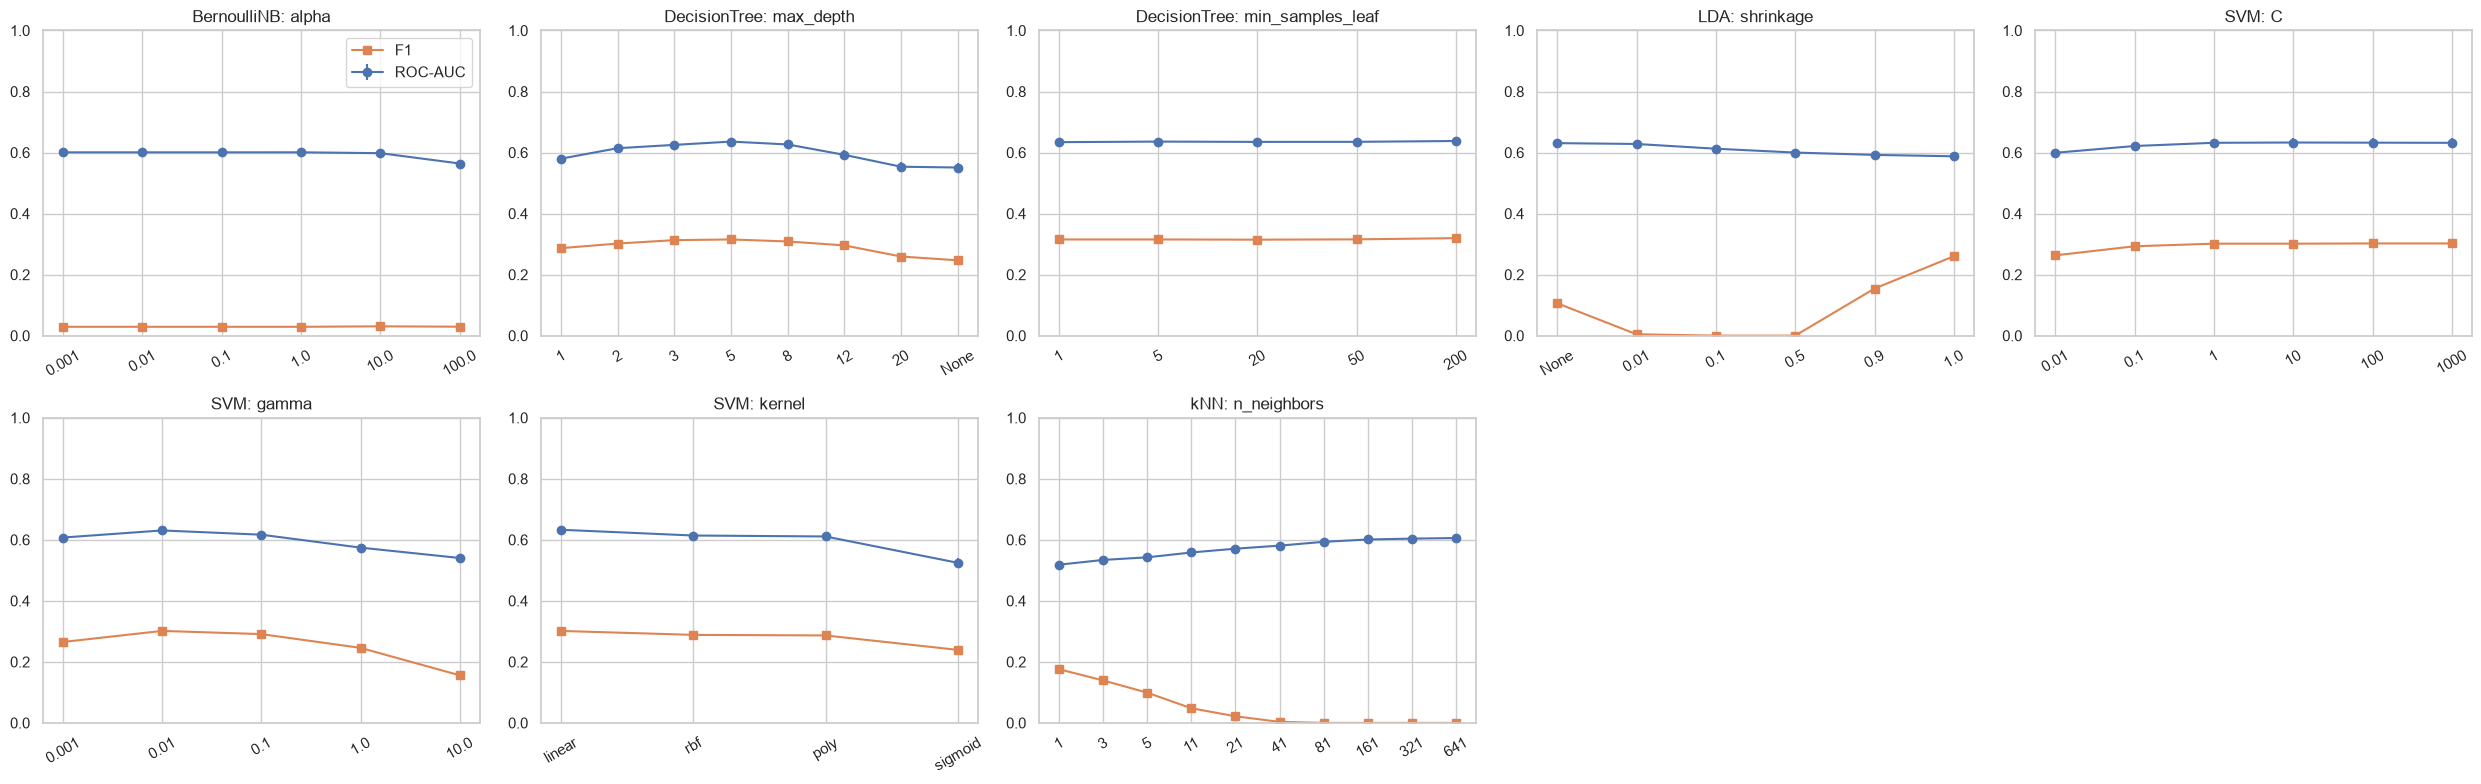

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(25, 8))
for ax, tab in zip(axes.ravel(), sweep_tables):
    x = np.arange(len(tab))
    ax.errorbar(x, tab["auc"], yerr=tab["auc_std"], marker="o", label="ROC-AUC")
    ax.plot(x, tab["f1"], marker="s", label="F1")
    ax.set_xticks(x)
    ax.set_xticklabels(tab["value"], rotation=30)
    ax.set_title(f'{tab["model"].iloc[0]}: {tab["param"].iloc[0]}')
    ax.set_ylim(0, 1)
axes.ravel()[0].legend()
for ax in axes.ravel()[len(sweep_tables):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "param_sweeps.png", dpi=130)
plt.show()

### Итоговые настроенные модели

Нейросеть и сравнение — в следующих разделах. Для наивного Байеса в сравнение берутся все четыре варианта, лучший по кросс-валидации — представитель метода.

In [12]:
final_models = {name: gs.best_estimator_ for name, gs in searches.items()}
final_models["SVM"] = clone(searches["SVM"].best_estimator_).fit(X_train, y_train)

tuned_rows = []
scores = {}
preds = {}
for name, model in final_models.items():
    preds[name] = model.predict(X_test)
    scores[name] = get_score(model, X_test)
    tuned_rows.append({"model": name, **compute_metrics(y_test, preds[name], scores[name])})

tuned_df = pd.DataFrame(tuned_rows).set_index("model")
tuned_df.to_csv(RES_DIR / "tuned_metrics.csv")
nb_names = ["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB"]
best_nb = best_df.loc[nb_names, "cv_auc"].idxmax()
print("лучший вариант НБ по CV AUC:", best_nb)
tuned_df.round(4)

лучший вариант НБ по CV AUC: BernoulliNB


,accuracy,precision,recall,f1,auc_roc
model,,,,,
GaussianNB,0.8260,0.2355,0.0830,0.1227,0.5768
MultinomialNB,0.8533,0.0000,0.0000,0.0000,0.5785
ComplementNB,0.6355,0.1869,0.4432,0.2629,0.5785
BernoulliNB,0.8530,0.4643,0.0148,0.0286,0.5769
DecisionTree,0.6110,0.2147,0.6216,0.3191,0.6451
LDA,0.8530,0.4000,0.0045,0.0090,0.6240
kNN,0.8533,0.5000,0.0034,0.0068,0.6007
SVM,0.5952,0.2006,0.5898,0.2994,0.6284


In [13]:
tree = final_models["DecisionTree"].named_steps["clf"]
prep_fitted = final_models["DecisionTree"].named_steps["prep"]
tree_features = prep_fitted.get_feature_names_out()
importances = pd.Series(tree.feature_importances_, index=tree_features).sort_values(ascending=False)
print("глубина:", tree.get_depth(), "| листьев:", tree.get_n_leaves())
print(importances.head(10).round(4))

глубина: 5 | листьев: 32
num__Number_of_Vehicles                         0.3445
cat__Urban_or_Rural_Area_Rural                  0.2154
num__Number_of_Casualties                       0.1327
cat__Road_Surface_Conditions_Dry                0.0585
cat__Road_Type_Single carriageway               0.0573
num__Latitude                                   0.0517
num__Longitude                                  0.0361
cat__Road_Type_Roundabout                       0.0287
cat__Light_Conditions_Daylight                  0.0209
cat__Vehicle_Type_Motorcycle 125cc and under    0.0137
dtype: float64


## 6. Нейронная сеть на TensorFlow

**Архитектура базовой модели** (`Sequential`): входной слой (число признаков после One-Hot), два скрытых `Dense(64, relu)`, выходной `Dense(1, sigmoid)` — вероятность тяжёлого ДТП. Функция потерь — `binary_crossentropy`, оптимизатор — `Adam(lr=1e-3)`, метрики — accuracy и AUC. Размер батча 256, 30 эпох.

Для валидации обучающая выборка делится ещё раз: 80% — обучение сети, 20% — валидация (`validation_data`). Из-за дисбаланса в `fit` передаётся `class_weight` (вес класса 1 = отношение числа объектов классов 0 и 1). Порог классификации 0.5. Тестовая выборка используется только для финальной оценки выбранной по валидации модели.

Эксперименты меняют по одному гиперпараметру относительно базовой конфигурации: размер батча, число слоёв, число нейронов, функцию активации, learning rate, число эпох. Каждый запуск пишет логи в `logs/<имя>` через `TensorBoard`-callback; просмотр: `tensorboard --logdir logs`.

In [14]:
X_nn_tr, X_nn_val, y_nn_tr, y_nn_val = train_test_split(
    Xtr, y_train.to_numpy(), test_size=0.2, stratify=y_train, random_state=SEED)

n_neg, n_pos = np.bincount(y_nn_tr)
CLASS_WEIGHT = {0: 1.0, 1: n_neg / n_pos}
print(X_nn_tr.shape, X_nn_val.shape, CLASS_WEIGHT)


def build_model(n_layers=2, units=64, activation="relu", lr=1e-3):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(Xtr.shape[1],))])
    for _ in range(n_layers):
        model.add(tf.keras.layers.Dense(units, activation=activation))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model


build_model().summary()

(19200, 48) (4800, 48) {0: 1.0, 1: np.float64(5.818181818181818)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,361 (28.75 KB)

 Trainable params: 7,361 (28.75 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
if LOG_DIR.exists():
    shutil.rmtree(LOG_DIR)

BASE_CFG = {"n_layers": 2, "units": 64, "activation": "relu", "lr": 1e-3, "batch_size": 256, "epochs": 30}

EXPERIMENTS = [
    ("base", "base", {}),
    ("epochs", "epochs_60", {"epochs": 60}),
    ("batch_size", "batch_64", {"batch_size": 64}),
    ("batch_size", "batch_1024", {"batch_size": 1024}),
    ("layers", "layers_1", {"n_layers": 1}),
    ("layers", "layers_3", {"n_layers": 3}),
    ("layers", "layers_4", {"n_layers": 4}),
    ("units", "units_16", {"units": 16}),
    ("units", "units_256", {"units": 256}),
    ("activation", "act_tanh", {"activation": "tanh"}),
    ("activation", "act_sigmoid", {"activation": "sigmoid"}),
    ("activation", "act_elu", {"activation": "elu"}),
    ("lr", "lr_1e-2", {"lr": 1e-2}),
    ("lr", "lr_1e-4", {"lr": 1e-4}),
]

histories = {}
nn_models = {}
exp_rows = []

for group, name, override in EXPERIMENTS:
    cfg = {**BASE_CFG, **override}
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(cfg["n_layers"], cfg["units"], cfg["activation"], cfg["lr"])
    tb = tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / name), histogram_freq=1)
    t0 = time.time()
    hist = model.fit(X_nn_tr, y_nn_tr, validation_data=(X_nn_val, y_nn_val),
                     epochs=cfg["epochs"], batch_size=cfg["batch_size"],
                     class_weight=CLASS_WEIGHT, callbacks=[tb], verbose=0)
    h = hist.history
    histories[name] = h
    nn_models[name] = model
    exp_rows.append({
        "group": group, "name": name, "layers": cfg["n_layers"], "units": cfg["units"],
        "activation": cfg["activation"], "lr": cfg["lr"], "batch": cfg["batch_size"], "epochs": cfg["epochs"],
        "train_loss": h["loss"][-1], "val_loss": h["val_loss"][-1],
        "val_acc": h["val_accuracy"][-1], "val_auc": h["val_auc"][-1],
        "best_val_auc": max(h["val_auc"]), "best_epoch": int(np.argmax(h["val_auc"])) + 1,
        "time_s": time.time() - t0,
    })
    print(f"{name:12s} val_auc={h['val_auc'][-1]:.4f} val_loss={h['val_loss'][-1]:.4f} "
          f"t={time.time() - t0:.0f}s")

exp_df = pd.DataFrame(exp_rows).set_index("name")
exp_df.to_csv(RES_DIR / "nn_experiments.csv")
exp_df.round(4)

base         val_auc=0.6192 val_loss=0.6945 t=5s


epochs_60    val_auc=0.6122 val_loss=0.7043 t=10s


batch_64     val_auc=0.6166 val_loss=0.6473 t=11s


batch_1024   val_auc=0.6267 val_loss=0.6696 t=4s


layers_1     val_auc=0.6334 val_loss=0.6770 t=4s


layers_3     val_auc=0.6152 val_loss=0.7476 t=6s


... (5 outputs left out)

act_elu      val_auc=0.6340 val_loss=0.6625 t=5s


lr_1e-2      val_auc=0.6074 val_loss=0.7960 t=5s


lr_1e-4      val_auc=0.6254 val_loss=0.6611 t=5s


,group,layers,units,activation,lr,batch,epochs,train_loss,val_loss,val_acc,val_auc,best_val_auc,best_epoch,time_s
name,,,,,,,,,,,,,,
base,base,2,64,relu,0.0010,256,30,1.0647,0.6945,0.5583,0.6192,0.6283,9,5.4163
epochs_60,epochs,2,64,relu,0.0010,256,60,1.0195,0.7043,0.5644,0.6122,0.6283,9,9.5231
batch_64,batch_size,2,64,relu,0.0010,64,30,1.0349,0.6473,0.6277,0.6166,0.6296,8,10.6922
batch_1024,batch_size,2,64,relu,0.0010,1024,30,1.0877,0.6696,0.5831,0.6267,0.6306,19,3.6795
layers_1,layers,1,64,relu,0.0010,256,30,1.1005,0.6770,0.5754,0.6334,0.6339,23,4.2397
layers_3,layers,3,64,relu,0.0010,256,30,1.0142,0.7476,0.5377,0.6152,0.6276,15,5.8210
layers_4,layers,4,64,relu,0.0010,256,30,0.9760,0.7521,0.5550,0.6076,0.6254,9,6.5068
units_16,units,2,16,relu,0.0010,256,30,1.1092,0.6806,0.5708,0.6372,0.6374,24,4.5195
units_256,units,2,256,relu,0.0010,256,30,0.9594,0.7483,0.5523,0.6037,0.6250,9,7.5814


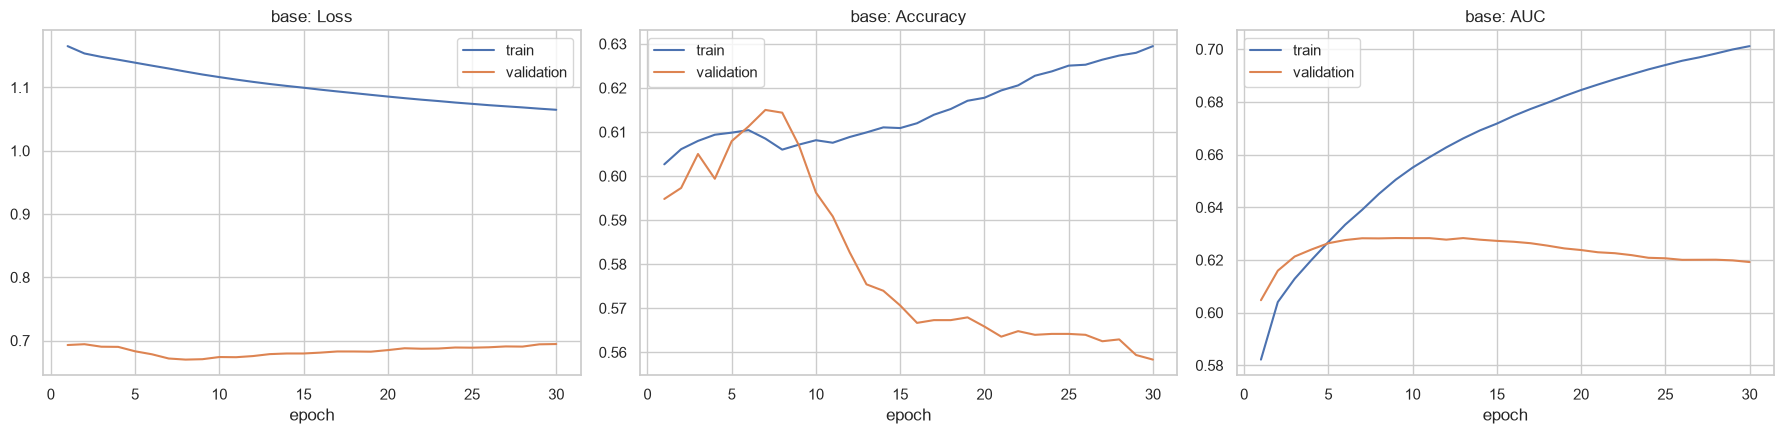

In [16]:
h = histories["base"]
epochs_axis = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, key, title in zip(axes, ["loss", "accuracy", "auc"], ["Loss", "Accuracy", "AUC"]):
    ax.plot(epochs_axis, h[key], label="train")
    ax.plot(epochs_axis, h["val_" + key], label="validation")
    ax.set_title(f"base: {title}")
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "nn_base_curves.png", dpi=130)
plt.show()

In [17]:
h60 = histories["epochs_60"]
ep_rows = [{"epochs": e, "train_loss": h60["loss"][e - 1], "val_loss": h60["val_loss"][e - 1],
            "val_acc": h60["val_accuracy"][e - 1], "val_auc": h60["val_auc"][e - 1]}
           for e in [5, 10, 20, 30, 45, 60]]
ep_df = pd.DataFrame(ep_rows).set_index("epochs")
ep_df.to_csv(RES_DIR / "nn_epochs.csv")
ep_df.round(4)

,train_loss,val_loss,val_acc,val_auc
epochs,,,,
5,1.1392,0.6830,0.6079,0.6264
10,1.1164,0.6739,0.5962,0.6283
20,1.0857,0.6849,0.5658,0.6238
30,1.0647,0.6945,0.5583,0.6192
45,1.0403,0.7012,0.5575,0.6141
60,1.0195,0.7043,0.5644,0.6122


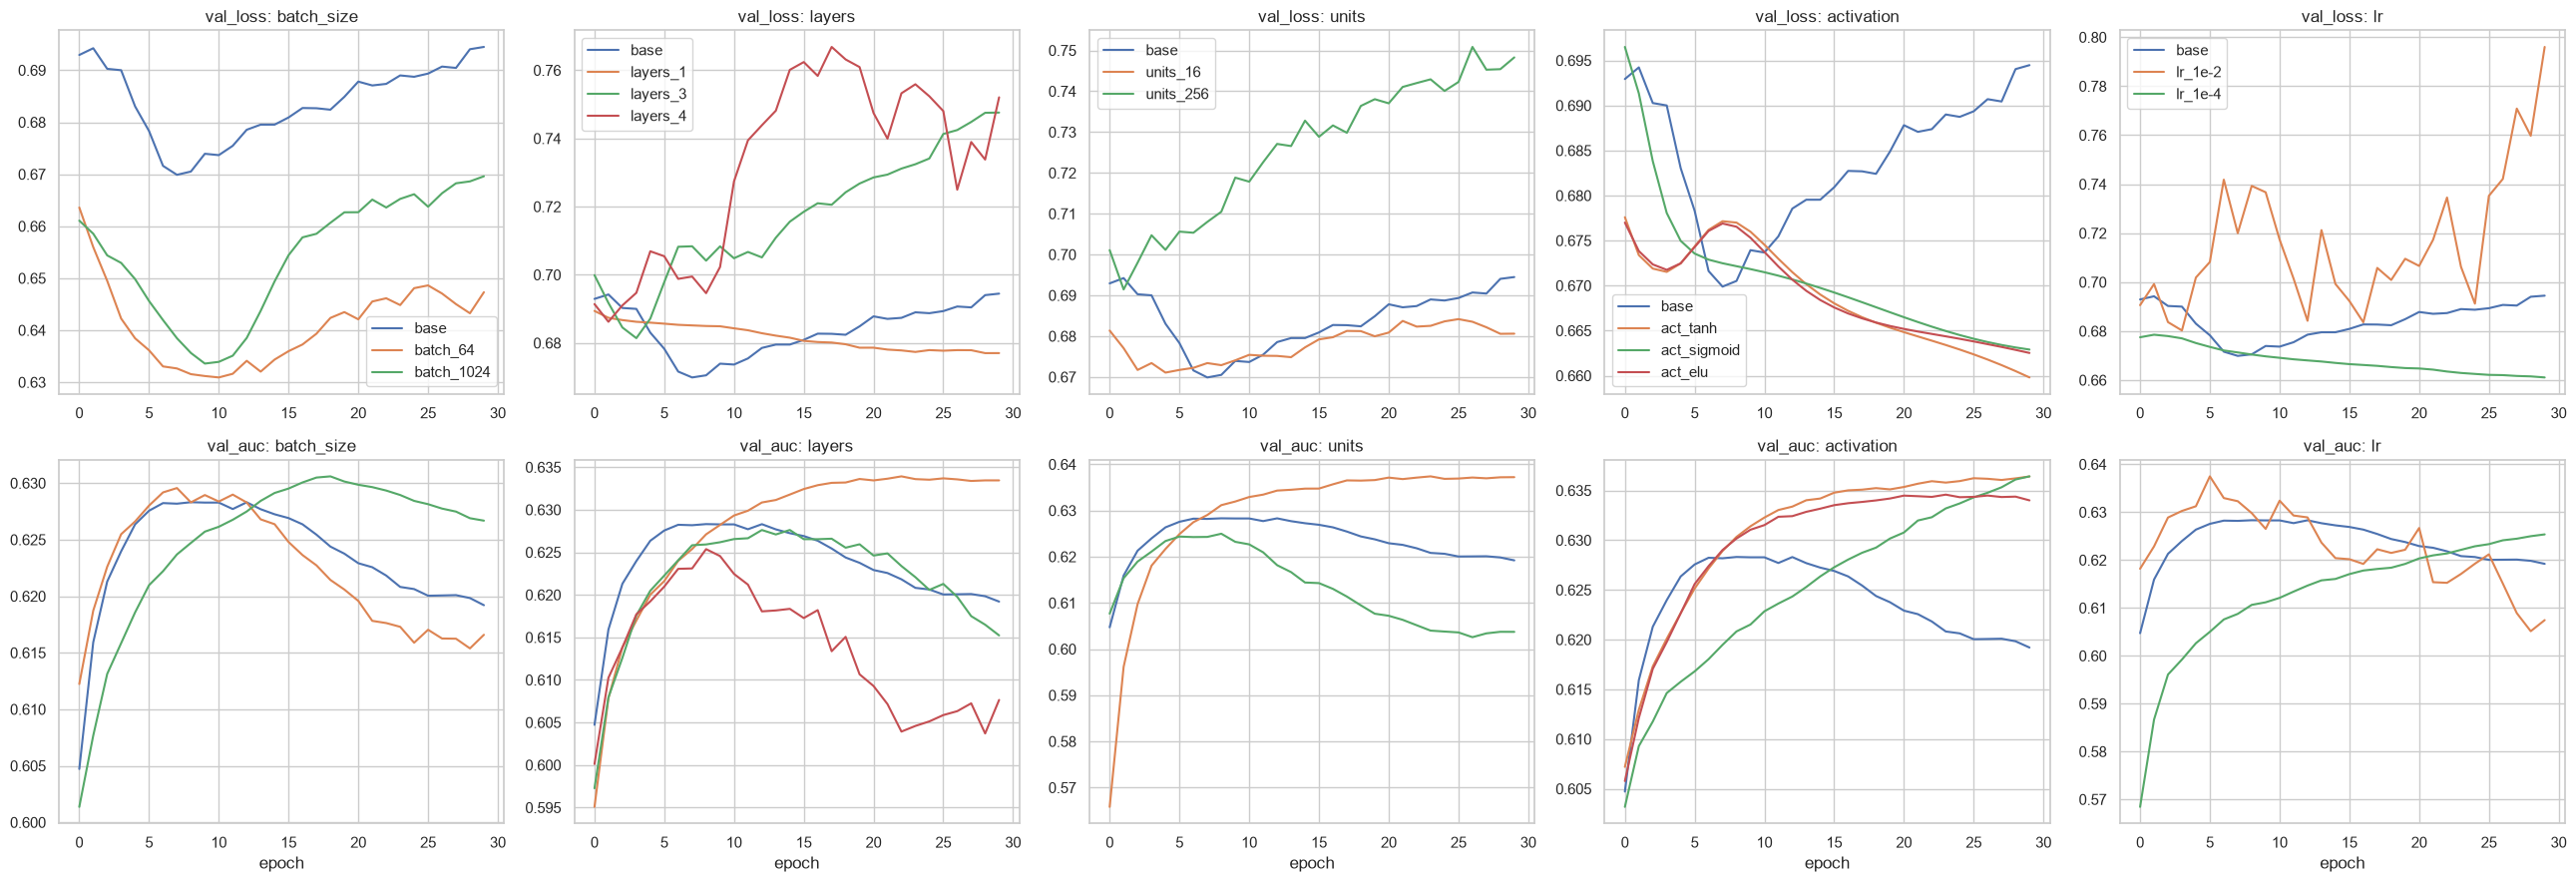

In [18]:
groups = ["batch_size", "layers", "units", "activation", "lr"]
members = {g: ["base"] + [n for gg, n, _ in EXPERIMENTS if gg == g] for g in groups}

fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for j, g in enumerate(groups):
    for n in members[g]:
        axes[0, j].plot(histories[n]["val_loss"], label=n)
        axes[1, j].plot(histories[n]["val_auc"], label=n)
    axes[0, j].set_title(f"val_loss: {g}")
    axes[1, j].set_title(f"val_auc: {g}")
    axes[0, j].legend()
    axes[1, j].set_xlabel("epoch")
plt.tight_layout()
plt.savefig(FIG_DIR / "nn_hyperparams.png", dpi=110)
plt.show()

In [19]:
best_nn_name = exp_df["val_auc"].idxmax()
best_nn = nn_models[best_nn_name]
nn_prob = best_nn.predict(Xte, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
nn_metrics = compute_metrics(y_test, nn_pred, nn_prob)
print("выбрана по val_auc:", best_nn_name)
print({k: round(v, 4) for k, v in nn_metrics.items()})
print("логи TensorBoard:", sorted(p.name for p in LOG_DIR.iterdir()))

выбрана по val_auc: units_16
{'accuracy': 0.5703, 'precision': 0.2, 'recall': 0.6432, 'f1': 0.3051, 'auc_roc': 0.6311}
логи TensorBoard: ['act_elu', 'act_sigmoid', 'act_tanh', 'base', 'batch_1024', 'batch_64', 'epochs_60', 'layers_1', 'layers_3', 'layers_4', 'lr_1e-2', 'lr_1e-4', 'units_16', 'units_256']


### Мониторинг в TensorBoard

```
tensorboard --logdir logs
```

Во вкладке **Scalars** отображаются `epoch_loss`, `epoch_accuracy`, `epoch_auc` для обучения и валидации, во вкладке **Histograms** — распределения весов слоёв (`histogram_freq=1`). Эксперименты выбираются слева (например, `base`, `batch_64`, `lr_1e-2`) и накладываются на один график.

## 7. Сравнительный анализ

In [20]:
nn_row = pd.DataFrame([{"model": "NeuralNetwork", **nn_metrics}]).set_index("model")
comparison_all = pd.concat([tuned_df, nn_row])
main_methods = [m for m in comparison_all.index if m not in nb_names or m == best_nb]
comparison = comparison_all.loc[main_methods]
comparison_all.to_csv(RES_DIR / "comparison_all.csv")
comparison.to_csv(RES_DIR / "comparison.csv")
print("Все модели на одной тестовой выборке:", len(y_test), "объектов")
comparison_all.round(4)

Все модели на одной тестовой выборке: 6000 объектов


,accuracy,precision,recall,f1,auc_roc
model,,,,,
GaussianNB,0.8260,0.2355,0.0830,0.1227,0.5768
MultinomialNB,0.8533,0.0000,0.0000,0.0000,0.5785
ComplementNB,0.6355,0.1869,0.4432,0.2629,0.5785
BernoulliNB,0.8530,0.4643,0.0148,0.0286,0.5769
DecisionTree,0.6110,0.2147,0.6216,0.3191,0.6451
LDA,0.8530,0.4000,0.0045,0.0090,0.6240
kNN,0.8533,0.5000,0.0034,0.0068,0.6007
SVM,0.5952,0.2006,0.5898,0.2994,0.6284
NeuralNetwork,0.5703,0.2000,0.6432,0.3051,0.6311


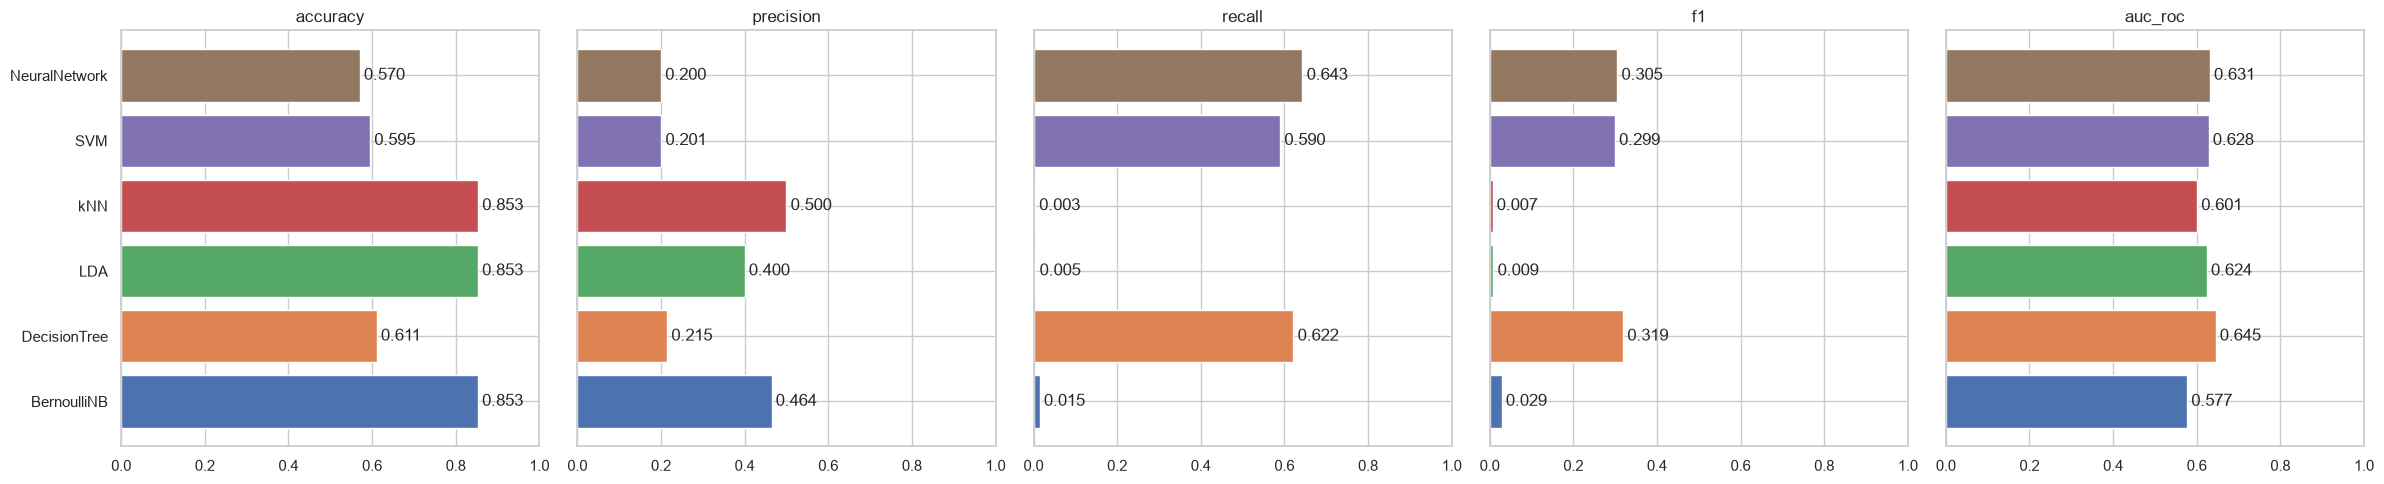

In [21]:
metric_names = ["accuracy", "precision", "recall", "f1", "auc_roc"]
fig, axes = plt.subplots(1, 5, figsize=(24, 5), sharey=True)
order = comparison.index.tolist()
for ax, m in zip(axes, metric_names):
    vals = comparison[m].loc[order]
    ax.barh(order, vals.values, color=sns.color_palette("deep", len(order)))
    ax.set_title(m)
    ax.set_xlim(0, 1)
    for i, v in enumerate(vals.values):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "metrics_bars.png", dpi=130)
plt.show()

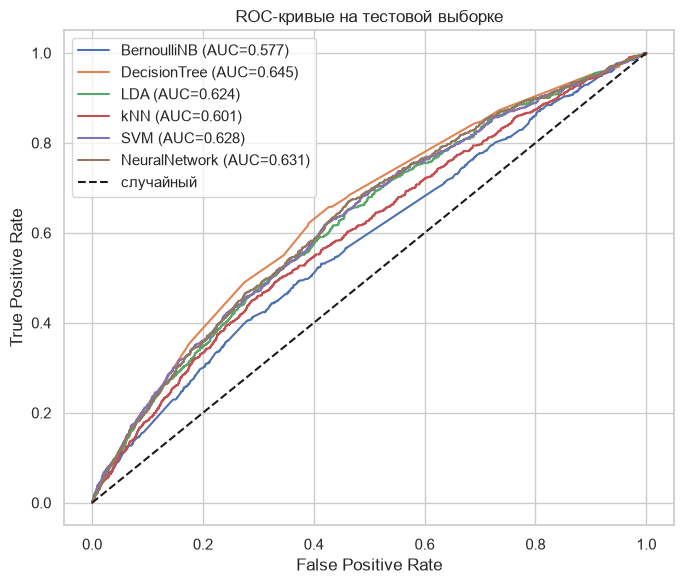

In [22]:
plt.figure(figsize=(7, 6))
for name in comparison.index:
    s = nn_prob if name == "NeuralNetwork" else scores[name]
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="случайный")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые на тестовой выборке")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_curves.png", dpi=130)
plt.show()

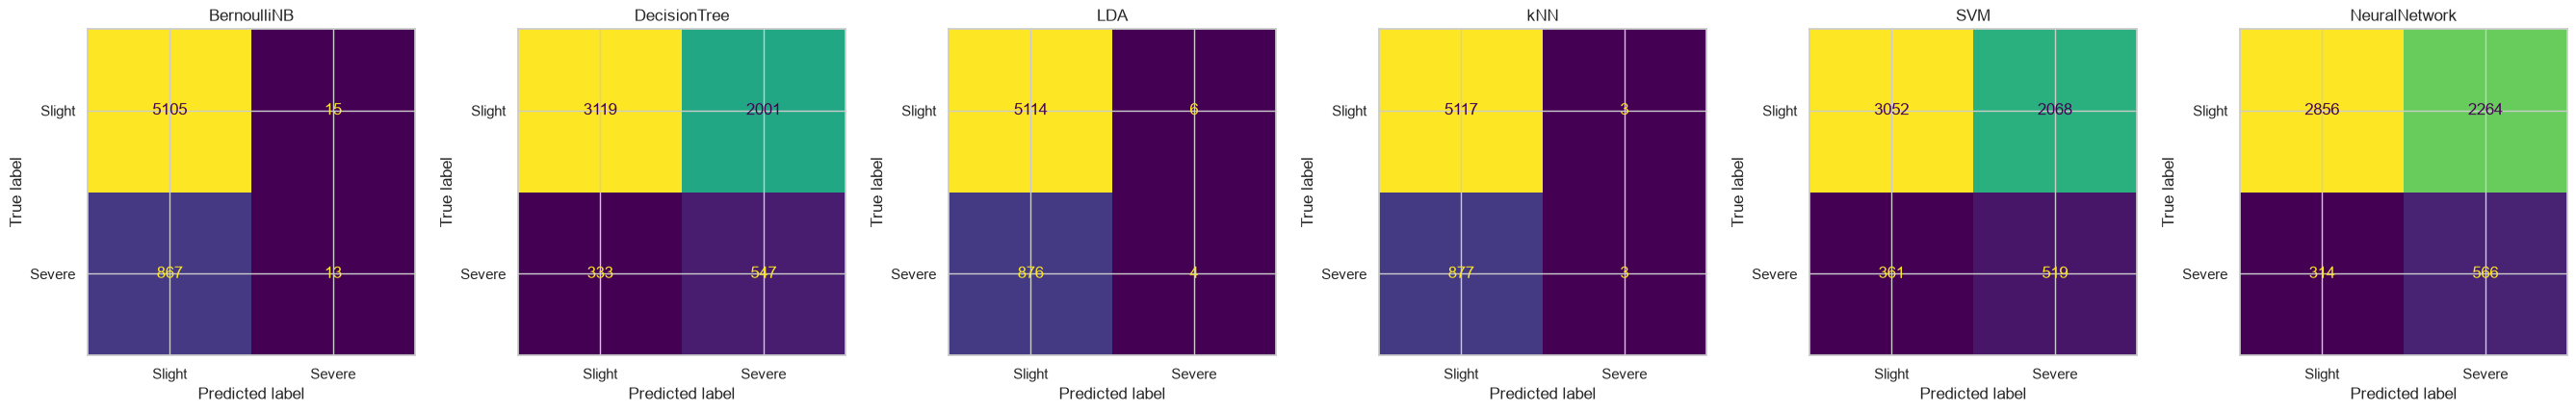

In [23]:
cm_models = {n: preds[n] for n in comparison.index if n != "NeuralNetwork"}
cm_models["NeuralNetwork"] = nn_pred
fig, axes = plt.subplots(1, len(cm_models), figsize=(4.5 * len(cm_models), 4.2))
for ax, (name, p) in zip(axes, cm_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["Slight", "Severe"],
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=130)
plt.show()

In [24]:
baseline_vs_tuned = pd.concat({"baseline": baseline_df[metric_names], "tuned": tuned_df[metric_names]}, axis=1)
baseline_vs_tuned.round(4)

baseline                                      tuned                                  
              accuracy precision  recall      f1 auc_roc accuracy precision  recall      f1 auc_roc
model                                                                                              
GaussianNB      0.1648    0.1479  0.9864  0.2573  0.5762   0.8260    0.2355  0.0830  0.1227  0.5768
MultinomialNB   0.8533    0.0000  0.0000  0.0000  0.5785   0.8533    0.0000  0.0000  0.0000  0.5785
ComplementNB    0.6328    0.1869  0.4489  0.2639  0.5785   0.6355    0.1869  0.4432  0.2629  0.5785
BernoulliNB     0.8483    0.2973  0.0250  0.0461  0.6179   0.8530    0.4643  0.0148  0.0286  0.5769
DecisionTree    0.7447    0.1772  0.2034  0.1894  0.5206   0.6110    0.2147  0.6216  0.3191  0.6451
LDA             0.8530    0.4000  0.0045  0.0090  0.6240   0.8530    0.4000  0.0045  0.0090  0.6240
SVM             0.8533    0.0000  0.0000  0.0000  0.5373   0.5952    0.2006  0.5898  0.2994  0.6284
kNN             0.8390    0.2133  0.0364  0.0621  0.5369   0.8533    0.5000  0.0034  0.0068  0.6007


### Выводы по разделу 5 (влияние гиперпараметров)

* **Наивный Байес.** Все варианты дают AUC 0.58–0.60 (CV), заметно слабее остальных методов — предположение о независимости признаков плохо выполняется (One-Hot признаки одной категории взаимоисключающи). `alpha` до 1 почти не влияет, при `alpha=100` AUC падает до 0.56 (сильное сглаживание стирает различия). `MultinomialNB` и `BernoulliNB` при пороге 0.5 почти всегда предсказывают класс «лёгкое ДТП» (recall ≈ 0), `ComplementNB` из-за поправки на дисбаланс даёт recall 0.44, а `GaussianNB` с `var_smoothing` по умолчанию, наоборот, предсказывает почти всё как «тяжёлое» (recall 0.99, accuracy 0.16).
* **Дерево решений.** Главный параметр — `max_depth`: при 1–2 уровнях модель недообучена (AUC 0.58–0.61), максимум при глубине 5 (0.636), при неограниченной глубине AUC падает до 0.55 — переобучение. `min_samples_leaf` влияет слабо. `class_weight="balanced"` резко повышает F1 (0.32 против ~0.19 у базового дерева).
* **LDA.** Решатель `svd` без shrinkage лучше по AUC (0.631); рост `shrinkage` ухудшает AUC (0.588 при 1.0): регуляризация ковариации здесь не нужна, признаков мало, а выборка велика.
* **SVM.** Линейное ядро лучше RBF (AUC 0.633 против 0.614), `sigmoid` хуже всех (0.52) — граница классов близка к линейной. `C` ≥ 1 выходит на плато (0.632), малые `C` недообучают (0.599 при 0.01). Для RBF оптимум `gamma=0.01` (0.631), большие `gamma` (≥1) резко ухудшают качество (переобучение). `class_weight="balanced"` поднимает recall с ~0 до ~0.6.
* **kNN.** AUC монотонно растёт с числом соседей: 0.518 при `k=1`, 0.606 при `k=641`; при малых `k` модель переобучена (шумные локальные оценки). Выбор `k=321` с `weights="distance"` и манхэттенской метрикой — лучший в сетке, но при пороге 0.5 класс 1 практически не предсказывается (recall ≈ 0).



### Выводы по разделу 6 (нейронная сеть)

* **Эпохи.** Лучшая валидационная AUC достигается на 9-й эпохе базовой модели (0.628); дальше `loss` на обучении продолжает падать (1.14 → 1.02 за 60 эпох), а `val_loss` растёт (0.68 → 0.70) и `val_auc` снижается — переобучение. Нужна ранняя остановка.
* **Размер батча.** 64 и 1024 дают практически тот же `val_auc` (0.617 и 0.627 в конце, максимум 0.630); малый батч быстрее сходится к переобучению, большой — медленнее.
* **Число слоёв и нейронов.** Более глубокие (3–4 слоя) и широкие (256) сети переобучаются быстрее (`val_loss` 0.75, `val_auc` 0.604–0.615); мелкие сети (1 слой, 16 нейронов) обобщают лучше (`val_auc` 0.633–0.637). Данные малоинформативны, избыточная ёмкость не помогает.
* **Функции активации.** `tanh`, `sigmoid`, `elu` дают близкие результаты (`val_auc` ≈ 0.634–0.636) и более плавную динамику, чем `relu` (0.619 в конце обучения).
* **Learning rate.** `1e-2` — самое быстрое переобучение (максимум `val_auc` на 6-й эпохе, к 30-й эпохе `val_loss` вырос до 0.80); `1e-4` — самое медленное и стабильное, к 30-й эпохе валидация ещё не ухудшается.
* **Итог.** По `val_auc` выбрана конфигурация `units_16` (2 слоя по 16 нейронов, relu, lr 1e-3, batch 256, 30 эпох): на тесте AUC 0.631, recall 0.643, F1 0.305. Кривые всех запусков доступны в TensorBoard (`logs/`).



## 7. Сравнительный анализ (выводы)

Доля класса «лёгкое ДТП» в тесте — 85.3%, поэтому классификатор, всегда отвечающий «лёгкое», получает accuracy 0.853 при recall = 0 и AUC = 0.5. Accuracy 0.853 у LDA, kNN и BernoulliNB — признак именно такого вырождения (recall 0.00–0.01), а не высокого качества. Для сравнения методов основными метриками выбраны **AUC-ROC** (не зависит от порога) и **F1/Recall по тяжёлому классу**.

| Метод | AUC-ROC | F1 | Recall | Комментарий |
|---|---|---|---|---|
| Дерево решений (depth=5, balanced) | **0.645** | **0.319** | 0.622 | лучшее по AUC и F1, интерпретируемо |
| Нейронная сеть (2x16, relu) | 0.631 | 0.305 | **0.643** | близка к дереву, лучший recall |
| SVM (linear, C=10, balanced) | 0.628 | 0.299 | 0.590 | сопоставим с сетью, но дороже в обучении |
| LDA (svd) | 0.624 | 0.009 | 0.005 | хорошее ранжирование, но порог 0.5 не подходит |
| kNN (k=321, distance) | 0.601 | 0.007 | 0.003 | слабее, нужен большой `k` |
| BernoulliNB | 0.577 | 0.029 | 0.015 | худший ранжирующий метод |

**Вывод.** Лучшим подходом для этого датасета является **дерево решений** ограниченной глубины с балансировкой классов: максимальные AUC (0.645) и F1 (0.319), простота, быстрое обучение и интерпретируемость (наиболее важные признаки — число транспортных средств, сельская местность, число пострадавших). Нейросеть и SVM дают близкое качество (AUC 0.63), но сложнее и не лучше. Абсолютные значения качества невелики (AUC ≤ 0.65): по условиям дороги, погоды и числу участников тяжесть ДТП предсказывается слабо — модель пригодна для ранжирования риска, но не для точной классификации. Для повышения качества нужны дополнительные признаки (скорость, возраст водителя, время суток) и подбор порога классификации под нужный баланс precision/recall.

Ограничения: сравнение выполнено на подвыборке 30 000 объектов; тестовая выборка (6 000 объектов, ≈ 880 тяжёлых) даёт доверительный интервал AUC порядка ±0.015, поэтому различия между деревом, сетью, SVM и LDA статистически не значимы.



## 8. Заключение

В работе на датасете ДТП (бинарная постановка: тяжёлое / лёгкое происшествие) построены и сравнены пять методов классификации Scikit-Learn (наивный Байес в четырёх вариантах, дерево решений, LDA, SVM, kNN) и нейронная сеть на TensorFlow/Keras. Гиперпараметры подбирались `GridSearchCV` по ROC-AUC с 3-кратной стратифицированной кросс-валидацией; влияние каждого параметра исследовано отдельными сериями экспериментов. Для сети проведено 14 запусков с изменением числа эпох, батча, слоёв, нейронов, активации и learning rate, обучение мониторилось в TensorBoard.

Основные результаты: качество всех моделей умеренное (AUC 0.58–0.65) из-за малой информативности признаков и дисбаланса классов; лучшим признано дерево решений глубины 5 с `class_weight="balanced"` (AUC 0.645, F1 0.319); балансировка классов и выбор метрик (AUC, F1 по классу 1 вместо accuracy) оказались важнее выбора конкретного алгоритма; переобучение нейронных сетей наблюдается быстро — нужны небольшая архитектура и ранняя остановка.
